# 國立陽明交通大學 - 多模態影像資料處理 (MMIP) 2026 Fall
## Assignment 04：時間序列模型與 Transformer（RNN / LSTM、Vision Transformer、Image Captioning）

- **學生**：林孟霆（`315833033`）
- **作業規範**：課程簡報第 55–58 頁（Quiz 1：10 分、Quiz 2：20 分、Quiz 3：35 分、Quiz 4：35 分）
- **完整文字報告與結果分析**：請見同目錄 `README.md`

### 在 Google Colab 執行（T4 GPU，約 1 小時）
1. 將 `HW04/` 資料夾壓縮成 `HW04.zip`，拖曳到 Colab 左側的「檔案」區。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. Quiz 4 需要 Gemini API Key：在 Colab 左側的 **🔑 Secrets** 新增名稱為 `GEMINI_API_KEY` 的密鑰，並開啟「Notebook access」。Key 不會寫進程式或 Notebook。
4. 「執行階段 → 全部執行」。訓練好的模型會存到 `Checkpoints/`，Gemini 的回覆會快取到 `Output/quiz4_gemini_cache.json`，重新執行時不會重新訓練、也不會重複呼叫 API。
5. 跑完後執行最後一格下載 `HW04_results.zip`，並用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。

In [2]:
%matplotlib inline
# 環境設定：支援上傳 HW04.zip 或使用 Google Drive 的 MyDrive/MMIP/HW04
import os, sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if os.path.exists('/content/HW04.zip') and not os.path.exists('/content/HW04/Code'):
        !unzip -q -o /content/HW04.zip -d /content/
    if os.path.exists('/content/HW04/Code'):
        os.chdir('/content/HW04')
    else:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/MMIP/HW04')
    !pip -q install bert-score google-genai

sys.path.insert(0, os.getcwd())

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Code.common import DEVICE
from Code.gemini import get_api_key

DATA_DIR, CKPT_DIR, OUT_DIR = 'Data', 'Checkpoints', 'Output'
for d in (DATA_DIR, CKPT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)
pd.set_option('display.max_colwidth', 120)
print(f"Working dir: {os.getcwd()}")
print(f"PyTorch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == 'cuda' else ''))
print('Gemini API key found' if get_api_key() else 'Gemini API key NOT found -> add GEMINI_API_KEY to Colab Secrets')

Working dir: /content/HW04
PyTorch 2.11.0+cu130 | device: cuda (Tesla T4)
Gemini API key found


---
## Quiz 1：資料集準備（基礎 10 分）

**簡報要求（第 55 頁）**
- （3 分）準備 Sentiment Analysis 所需的文字分類資料集。
- （4 分）準備 Image Classification 所需的影像分類資料集。
- （3 分）準備 Image Captioning 所需的影像－文字描述資料集。

**本作業做法**（三個都是公開的標準資料集，由 Hugging Face 自動下載）
| 任務 | 資料集 | 切分 |
| :--- | :--- | :--- |
| Sentiment Analysis | IMDB Large Movie Review（正面 / 負面影評） | 官方 25,000 訓練中分層切出 2,500 驗證；官方 25,000 測試 |
| Image Classification | Oxford-IIIT Pet（37 種貓狗品種） | 官方 3,680 trainval 中分層切出 15% 驗證；官方 3,669 測試 |
| Image Captioning | Flickr8k（每張影像 5 句人工描述） | 官方 6,000 訓練 / 1,000 驗證 / 1,000 測試 |

QUIZ 1: DATASETS
                         task                 dataset                hf_id              classes / targets  train  val  test                                            notes
  Sentiment Analysis (Quiz 2) IMDB Large Movie Review     stanfordnlp/imdb            negative / positive  22500 2500 25000                  median review length 175 tokens
Image Classification (Quiz 3)         Oxford-IIIT Pet timm/oxford-iiit-pet            37 cat & dog breeds   3128  552  3669 fine-grained, roughly 100 train images per class
    Image Captioning (Quiz 4)                Flickr8k        jxie/flickr8k 5 reference captions per image   6000 1000  1000        30,000 training captions, median 10 words


,task,dataset,hf_id,classes / targets,train,val,test,notes
0,Sentiment Analysis (Quiz 2),IMDB Large Movie Review,stanfordnlp/imdb,negative / positive,22500,2500,25000,median review length 175 tokens
1,Image Classification (Quiz 3),Oxford-IIIT Pet,timm/oxford-iiit-pet,37 cat & dog breeds,3128,552,3669,"fine-grained, roughly 100 train images per class"
2,Image Captioning (Quiz 4),Flickr8k,jxie/flickr8k,5 reference captions per image,6000,1000,1000,"30,000 training captions, median 10 words"


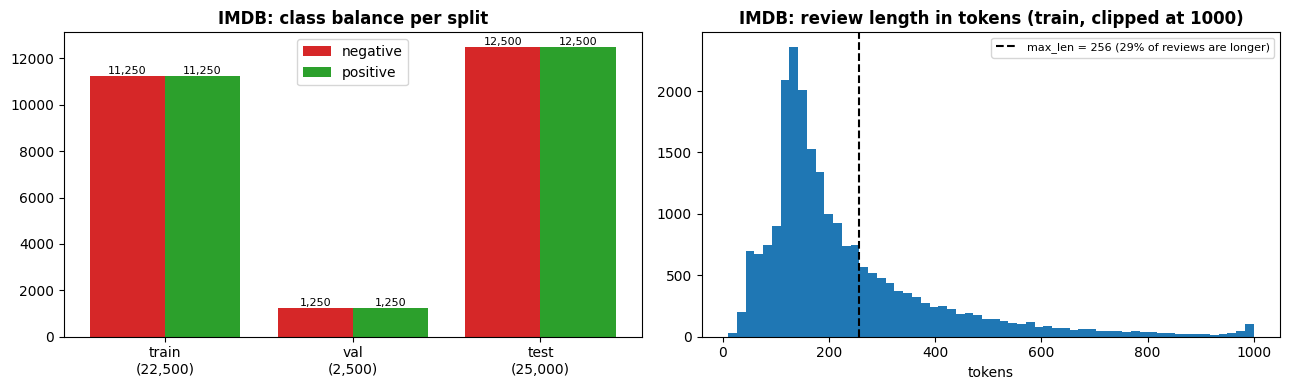

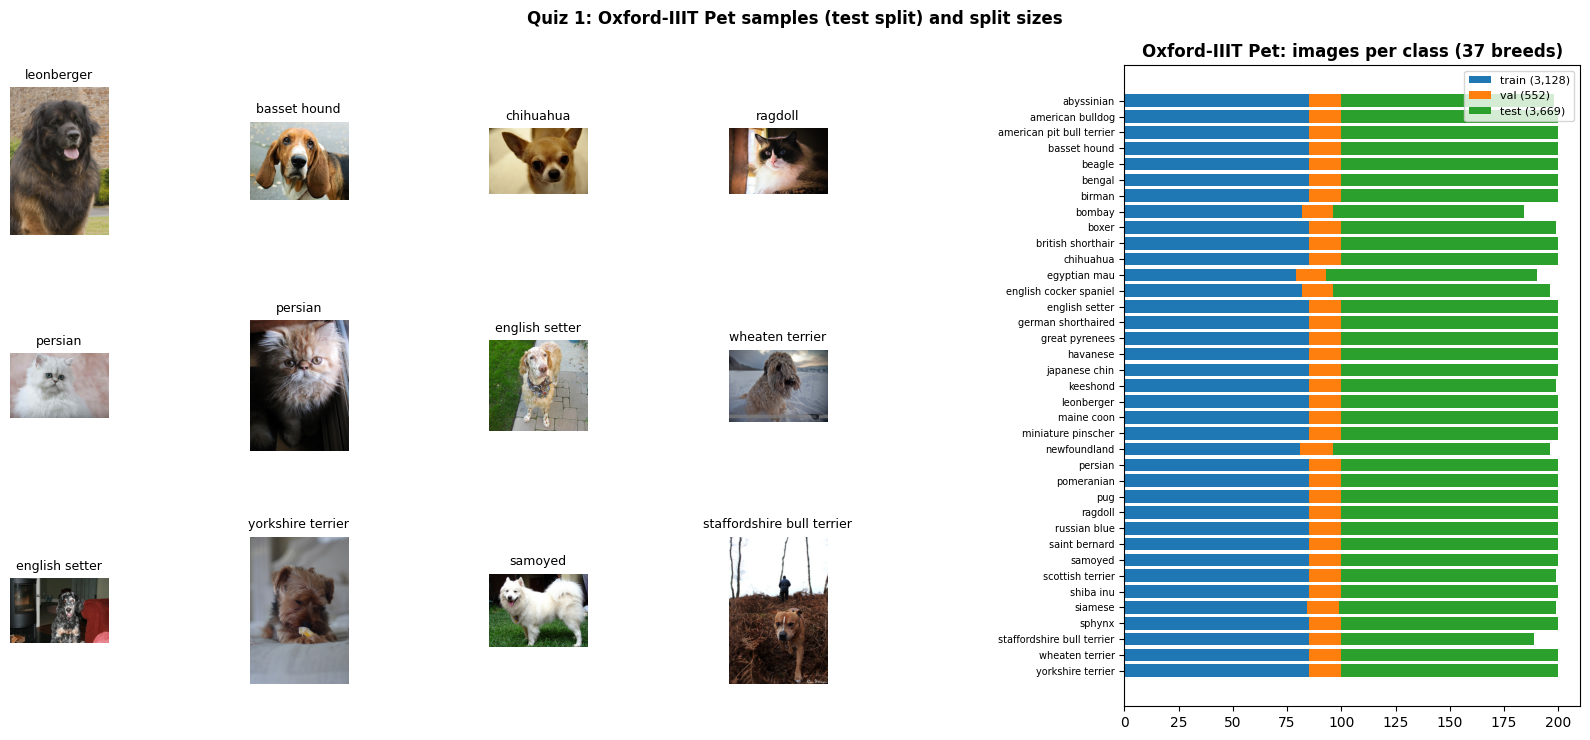

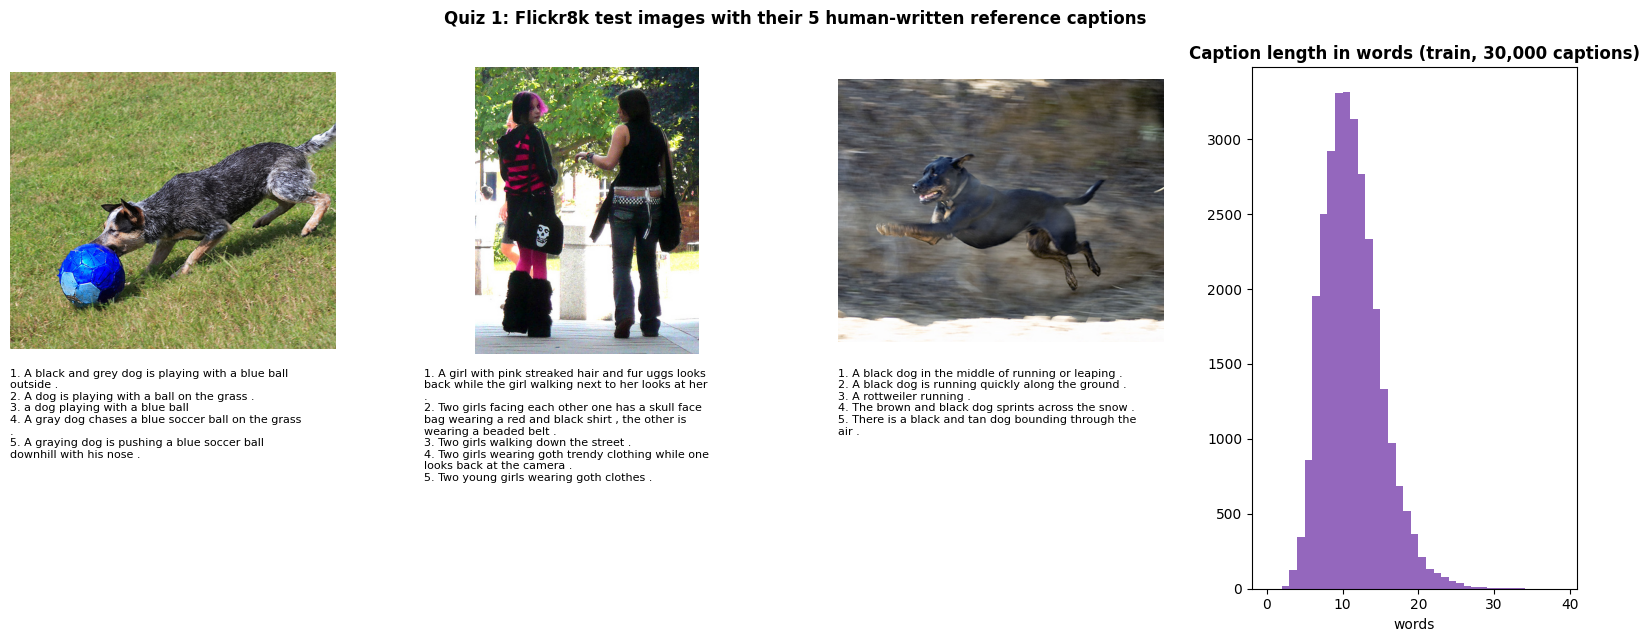

IMDB 範例（訓練集）：


,label,review
0,negative,"""Algie, the Miner"" is one bad and unfunny silent comedy. The timing of the slapstick is completely off. This is the ..."
1,negative,This is a complete Hoax... The movie clearly has been shot in north western Indian state of Rajasthan. Look at the ...
2,positive,"Nifty little episode played mainly for laughs, but with clever dollop of suspense. Somehow a Martian has snuck aboar..."
3,negative,Perhaps the worst thing about Carlos Mencia's comedy is that every joke needs to be followed with an insult at the p...


In [3]:
from Code.data import load_imdb, load_pets, load_flickr8k
from Code.quiz1_datasets import run_quiz1
from Code.quiz2_sentiment import MAX_LEN

imdb, pets, flickr = load_imdb(DATA_DIR), load_pets(DATA_DIR), load_flickr8k(DATA_DIR)
q1 = run_quiz1(imdb, pets, flickr, OUT_DIR, MAX_LEN)
plt.close('all')
display(q1['table'])
for k in ('imdb', 'pets', 'flickr'):
    display(q1['figures'][k])
print('IMDB 範例（訓練集）：')
display(pd.DataFrame({'label': [imdb['class_names'][y] for y in imdb['train'][1][:4]],
                      'review': [t.replace('<br />', ' ')[:200] for t in imdb['train'][0][:4]]}))

---
## Quiz 2：Sentiment Analysis（基礎 10 分 + 進階 10 分）

**簡報要求（第 56 頁）**
- 基礎：（5 分）建立並訓練 RNN 模型，完成文字分類任務；（5 分）使用測試資料進行推論，並呈現分類結果。
- 進階：（5 分）建立並訓練 LSTM 模型，完成文字分類任務；（5 分）透過合適的表現評估指標比較 RNN 與 LSTM 的表現。

**設計**：兩個模型除了循環單元（`nn.RNN` vs `nn.LSTM`）之外完全相同，比較結果才能歸因於模型本身。
- 前處理：小寫、去除 `<br />`、以字詞切分；詞彙表取訓練集出現 ≥ 2 次的前 20,000 個字。
- 每則評論保留**最後 256 個 token**（評論的總結評價通常在結尾），並用 packed sequence 讓循環在真實長度停止，最後的 hidden state 不會被 padding 影響。
- 架構：Embedding(128) → 單層 RNN / LSTM(128) → Dropout(0.3) → Linear(2)。
- 訓練：Adam（lr 1e-3；程式中以 weight decay = 0 的 AdamW 實作，與 Adam 等價）、batch 64、10 epochs、梯度裁剪 1.0；保留 Validation Accuracy 最高的 epoch。
- 評估指標：Accuracy、Precision、Recall、F1、ROC-AUC、混淆矩陣，以及**依評論長度分組的 Accuracy**（觀察長序列上的差異）。

In [4]:
from Code.quiz2_sentiment import run_quiz2
q2 = run_quiz2(imdb, CKPT_DIR, OUT_DIR)
plt.close('all')
display(q2['table'])

QUIZ 2: SENTIMENT ANALYSIS (RNN vs LSTM)
Vocabulary: 20,002 tokens (top 20,000 training words with frequency >= 2, plus <pad>/<unk>)
[cache] quiz2_rnn: loaded best-val checkpoint (epoch 10, val acc 0.8240)
[cache] quiz2_lstm: loaded best-val checkpoint (epoch 9, val acc 0.8764)
model  params  best_epoch  best_val_acc  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  acc_len_<=128  acc_len_129-256  acc_len_>256 (truncated)  train_minutes
  RNN 2593538          10        0.8240         0.8172          0.8002       0.8457   0.8223        0.8924         0.8464           0.8119                    0.7980           0.95
 LSTM 2692610           9        0.8764         0.8805          0.8772       0.8848   0.8810        0.9466         0.8897           0.8863                    0.8622           0.98


,model,params,best_epoch,best_val_acc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,acc_len_<=128,acc_len_129-256,acc_len_>256 (truncated),train_minutes
0,RNN,2593538,10,0.8240,0.8172,0.8002,0.8457,0.8223,0.8924,0.8464,0.8119,0.7980,0.95
1,LSTM,2692610,9,0.8764,0.8805,0.8772,0.8848,0.8810,0.9466,0.8897,0.8863,0.8622,0.98


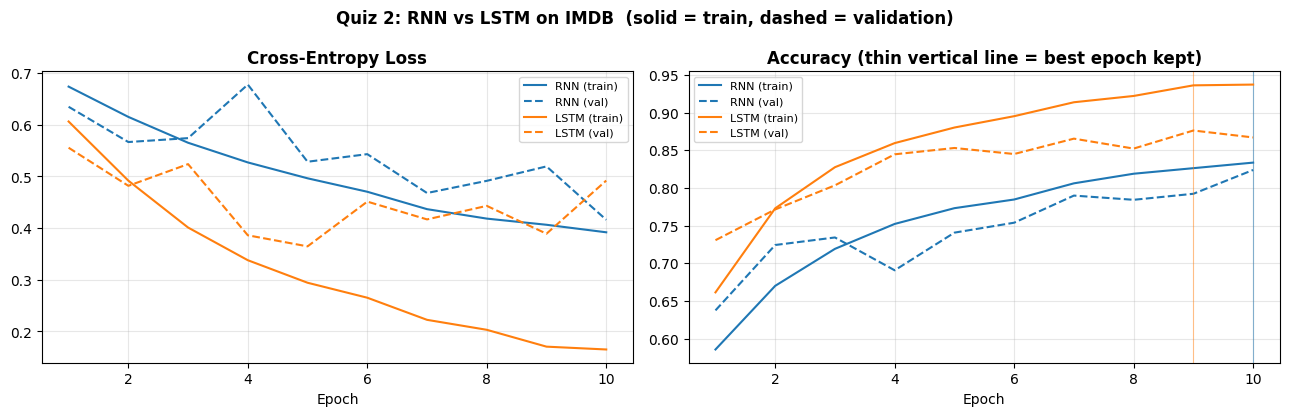

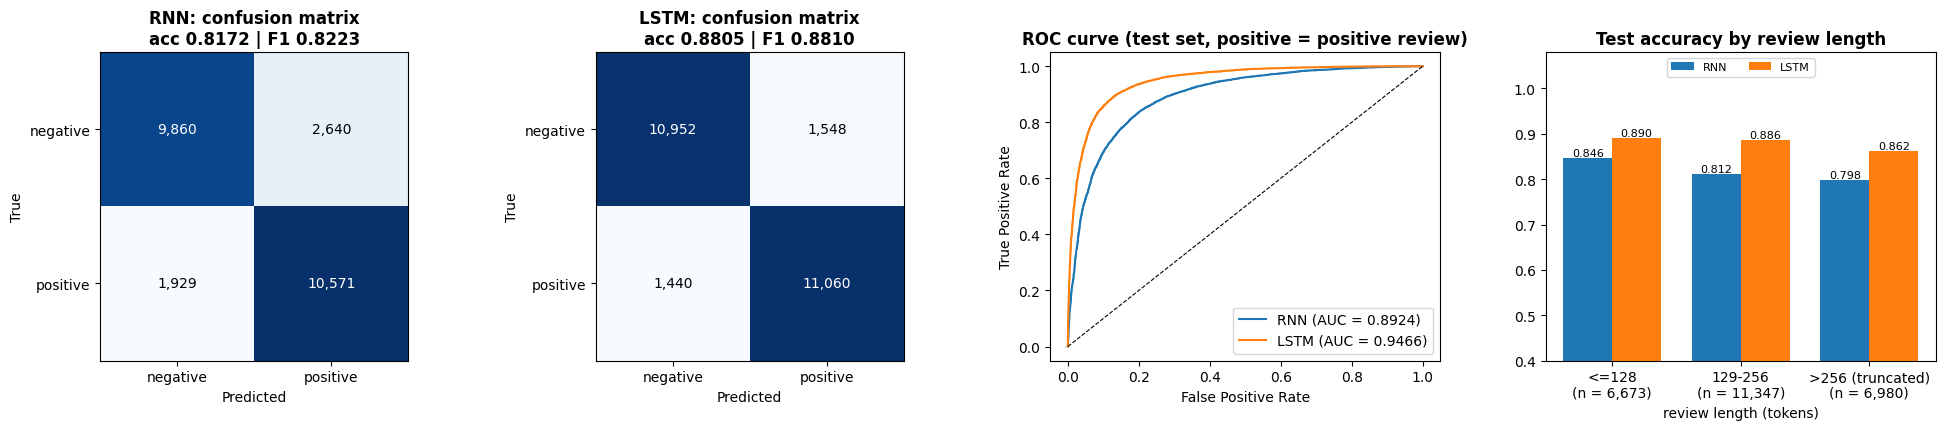

測試資料推論結果（8 則隨機測試評論 + 4 則自行撰寫的評論）：


,source,review (first 120 chars),true,RNN prediction,LSTM prediction
0,test #21259,This movie is a masterpiece of brilliant acting and timely patriotic sense of pride in America. The Nazi Saboteurs o...,positive,positive (0.96),positive (1.00)
1,test #1880,"Anatomie isn't very unique in horror genre, in fact it isn't even scary at all. It reminds me of its American cousin...",negative,negative (0.97),negative (1.00)
2,test #413,"I love the so-called ""blaxploitation"" films and have seen dozens. Some, such as COTTON COMES TO HARLEM, SHAFT and HA...",negative,negative (0.88),negative (1.00)
3,test #12775,This is another one of Hitchcock's highest rated movies and rightfully so. This is a tale of two men who meet on a t...,positive,positive (0.80),positive (1.00)
4,test #7694,"This appears to be one of Noel Coward's lesser known films, and it is easy to understand why. Taken at face value it...",negative,positive (0.93),positive (0.74)
5,test #6743,A poor basketball movie. A gruff coach with a dubious background comes to a small Indiana high school basketball tea...,negative,negative (0.72),negative (0.99)
6,test #1024,"Let me first start with the obvious: antisemitism has been a serious problem throughout history, present in many soc...",negative,negative (0.83),positive (0.93)
7,test #15920,"Overall, the Dad's Army movie is very funny, although the humour isn't quite as catchy and sparkly as in the TV and ...",positive,positive (0.81),positive (0.95)
8,custom,"This movie was absolutely wonderful, the acting and the story were brilliant.",positive,positive (0.77),positive (0.93)
9,custom,A complete waste of time. The plot made no sense and the acting was terrible.,negative,negative (0.95),negative (1.00)


In [5]:
display(q2['figures']['curves'])
display(q2['figures']['evaluation'])
print('測試資料推論結果（8 則隨機測試評論 + 4 則自行撰寫的評論）：')
display(q2['examples'])

---
## Quiz 3：Vision Transformer（基礎 20 分 + 進階 15 分）

**簡報要求（第 57 頁）**
- 基礎：（20 分）微調 Vision Transformer（ViT），並成功完成影像分類推論。
- 進階：（10 分）微調 ResNet，並成功完成影像分類推論；（5 分）與 ViT 比較 Macro-AUC 表現。

**設計**：兩個模型都載入 ImageNet 預訓練權重、換成 37 類的輸出層後**全部微調**，並使用完全相同的訓練設定。
- 模型：ViT-B/16（torchvision `IMAGENET1K_V1`，約 8,580 萬參數）、ResNet-50（torchvision `IMAGENET1K_V2`，約 2,360 萬參數）。
- 資料擴增（只用於訓練）：RandomResizedCrop(224, scale 0.6–1.0)、水平翻轉；驗證 / 測試：Resize 256 → CenterCrop 224。
- 訓練：AdamW（lr 1e-4、weight decay 0.05）、1 epoch warm-up + cosine 衰減、batch 32、8 epochs、混合精度（AMP）。
- 評估：Top-1 / Top-5、Macro-AUC（37 類 one-vs-rest 平均）、各類別 AUC、Macro-average ROC 曲線。

QUIZ 3: VISION TRANSFORMER vs RESNET-50 (Oxford-IIIT Pet)
[cache] quiz3_vit_b_16: loaded best-val checkpoint (epoch 7, val acc 0.9547)
[cache] quiz3_resnet50: loaded best-val checkpoint (epoch 8, val acc 0.9529)
    model   params  best_epoch  best_val_acc  test_top1  test_top5  test_macro_auc  train_minutes  test_images_per_sec
 ViT-B/16 85827109           7       0.95471     0.9305     0.9954        0.998246           5.78                160.4
ResNet-50 23583845           8       0.95290     0.9275     0.9956        0.998185           3.01                186.6


,model,params,best_epoch,best_val_acc,test_top1,test_top5,test_macro_auc,train_minutes,test_images_per_sec
0,ViT-B/16,85827109,7,0.95471,0.9305,0.9954,0.998246,5.78,160.4
1,ResNet-50,23583845,8,0.95290,0.9275,0.9956,0.998185,3.01,186.6


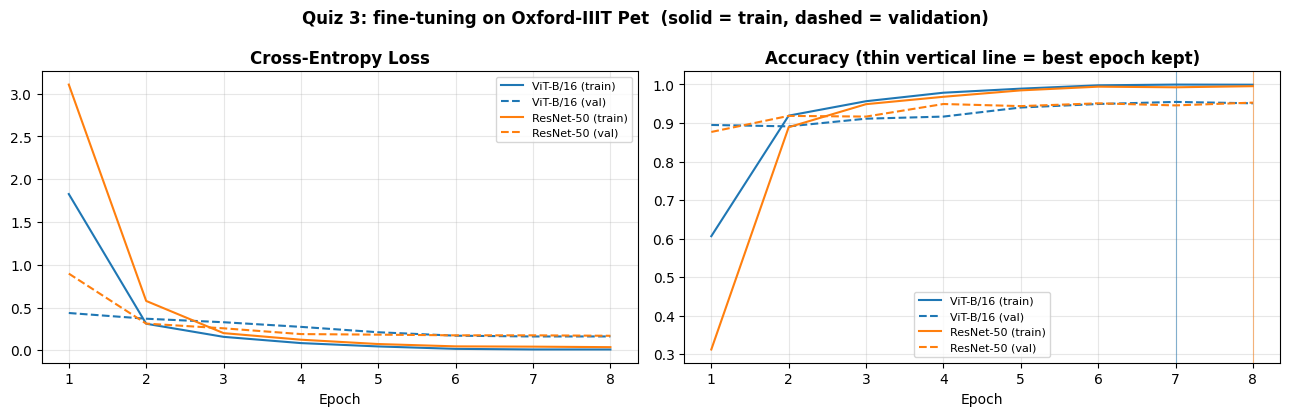

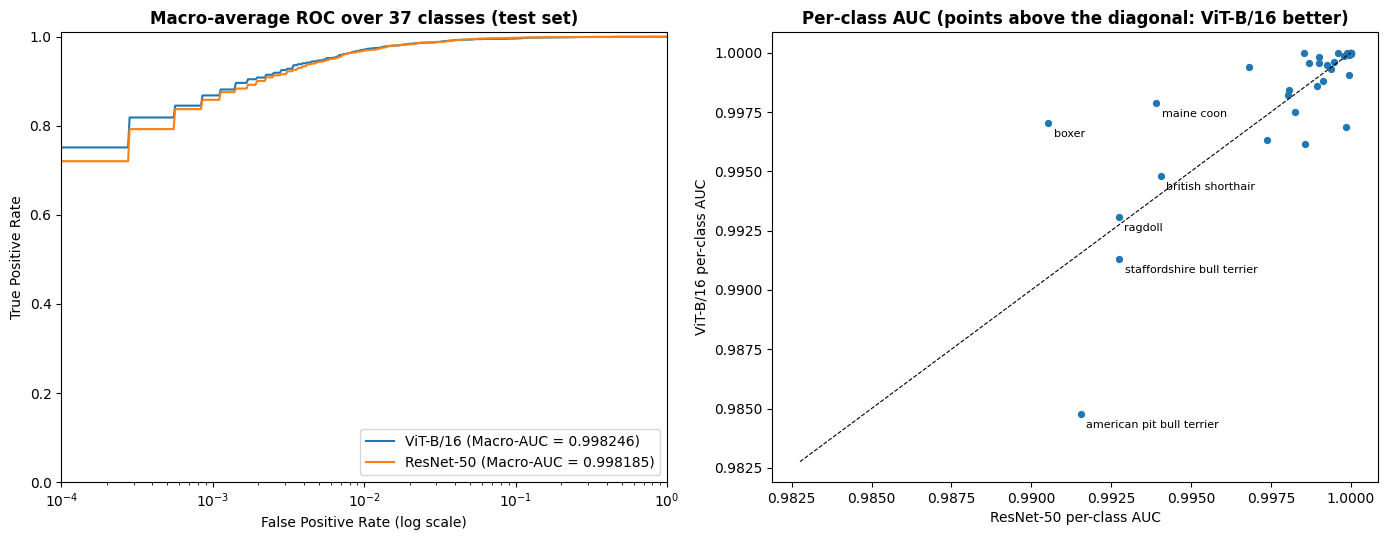

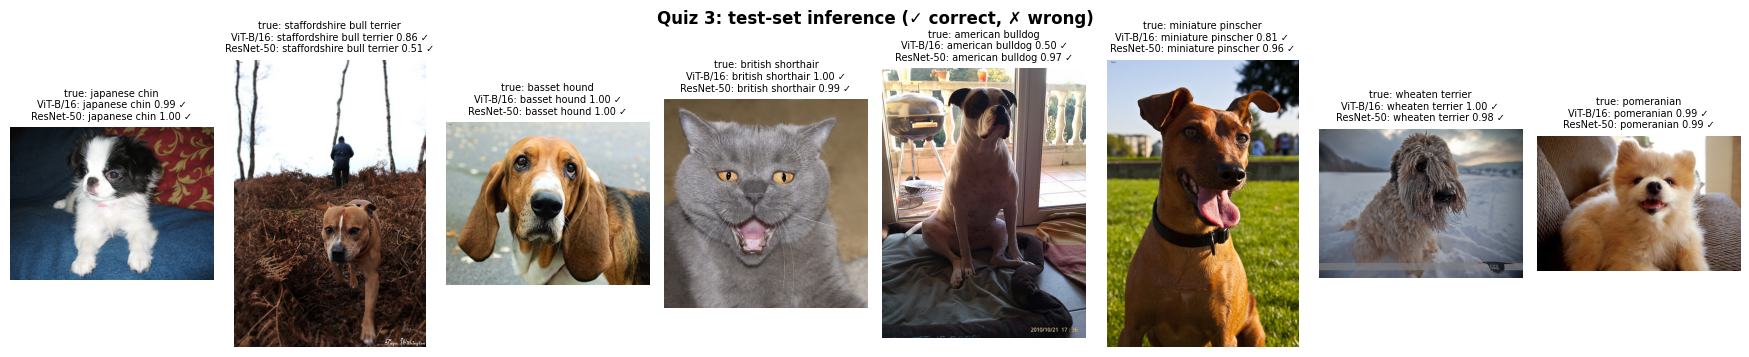

ViT-B/16 最常見的錯誤（真實 -> 預測）：


,count
american pit bull terrier -> staffordshire bull terrier,21
egyptian mau -> bengal,20
ragdoll -> birman,17
american pit bull terrier -> american bulldog,15
birman -> ragdoll,12


ResNet-50 最常見的錯誤（真實 -> 預測）：


,count
american pit bull terrier -> staffordshire bull terrier,28
egyptian mau -> bengal,11
birman -> ragdoll,11
russian blue -> bombay,11
american pit bull terrier -> american bulldog,10


In [6]:
from Code.quiz3_vit import run_quiz3
q3 = run_quiz3(pets, CKPT_DIR, OUT_DIR)
plt.close('all')
display(q3['table'])
display(q3['figures']['curves'])
display(q3['figures']['comparison'])
display(q3['figures']['samples'])
for name, pairs in q3['confused'].items():
    print(f'{name} 最常見的錯誤（真實 -> 預測）：')
    display(pairs.to_frame('count'))

---
## Quiz 4：Image Captioning（基礎 20 分 + 進階 15 分）

**簡報要求（第 58 頁）**
- 基礎：（15 分）訓練 Image Captioning 模型，並成功產生影像描述；（5 分）使用 Gemini 判斷模型產生的描述是否符合影像內容。
- 進階：（5 分）透過 BLEU 或是 BERTScore 量化模型表現；（10 分）比較不同方法的回覆時間與表現，並整理實驗結果。

**自行訓練的兩個模型**（影像編碼器都是凍結的 ImageNet ResNet-50，輸出 7×7 = 49 個區域特徵）
- **CNN-LSTM**（類似 Show and Tell）：影像特徵平均後初始化 LSTM 的狀態，LSTM 逐字產生描述。
- **CNN-Transformer**：3 層 Transformer Decoder，Masked Self-Attention 看已產生的字、Cross-Attention 看 49 個影像區域。
- 訓練：AdamW（lr 3e-4）、warm-up + cosine、batch 128、15 epochs；保留 Validation BLEU-4 最高的 epoch。

**比較的六種方法**：上述兩個模型 × {Greedy、Beam Search (k = 3)}、預訓練的 BLIP-base（未在 Flickr8k 上訓練，zero-shot）、Gemini（`gemini-3.5-flash-lite`）直接看圖寫描述。
- **表現**：BLEU-1~4 與 BERTScore F1（和 5 句人工描述比較）。本地方法用完整 1,000 張測試影像評估。
- **回覆時間**：在同一批 20 張測試影像上，逐張量測「從影像到描述」的端對端時間（batch size 1）。
- **Gemini 判斷**：同 20 張影像（受免費 API 額度限制，以固定亂數種子從測試集隨機抽出），每張影像把所有方法的描述加上一句人工描述（對照組）打亂順序、以 A/B/C… 匿名後一次送給 Gemini，請它判斷 match / partial / mismatch 並給 1–5 分。Gemini 只看到字母，不知道描述來自哪個方法。

In [10]:
from Code.quiz4_captioning import run_quiz4
q4 = run_quiz4(flickr, DATA_DIR, CKPT_DIR, OUT_DIR, gemini_model='gemini-3.5-flash-lite', n_subset=20)
plt.close('all')
print('完整測試集（1,000 張）的 BLEU / BERTScore：')
display(q4['full_table'])
print(f"同一批 {len(q4['subset'])} 張測試影像上的回覆時間、表現與 Gemini 判斷（Gemini 模型：{q4['gemini_model']}）：")
display(q4['subset_table'])

QUIZ 4: IMAGE CAPTIONING (Flickr8k)
Caption vocabulary: 2,533 words (frequency >= 5 in training captions)
[cache] quiz4_cnn_lstm: loaded best checkpoint (epoch 13, val BLEU-4 0.1729)
[cache] quiz4_cnn_transformer: loaded best checkpoint (epoch 8, val BLEU-4 0.1886)


[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


            method  BLEU-1  BLEU-2  BLEU-3  BLEU-4  BERTScore_F1
       LSTM greedy  0.5866  0.4127  0.2787  0.1866        0.5680
        LSTM beam3  0.6183  0.4414  0.3077  0.2119        0.5838
Transformer greedy  0.5847  0.4091  0.2784  0.1882        0.5621
 Transformer beam3  0.6164  0.4373  0.3053  0.2087        0.5803
         BLIP-base  0.6420  0.4910  0.3636  0.2672        0.6067
Gemini model: gemini-3.5-flash-lite (40 API calls at most, cached in Output/quiz4_gemini_cache.json)
            method  BLEU-4  BERTScore_F1  mean_latency_ms  median_latency_ms  gemini_mean_score  gemini_match_rate  trainable_params
       LSTM greedy  0.2024        0.5819             17.7               17.4               2.80               0.35         6795749.0
        LSTM beam3  0.1237        0.5888             18.3               17.9               3.00               0.40         6795749.0
Transformer greedy  0.2127        0.5933             48.6               45.3               2.55               

,method,BLEU-1,BLEU-2,BLEU-3,BLEU-4,BERTScore_F1
0,LSTM greedy,0.5866,0.4127,0.2787,0.1866,0.5680
1,LSTM beam3,0.6183,0.4414,0.3077,0.2119,0.5838
2,Transformer greedy,0.5847,0.4091,0.2784,0.1882,0.5621
3,Transformer beam3,0.6164,0.4373,0.3053,0.2087,0.5803
4,BLIP-base,0.6420,0.4910,0.3636,0.2672,0.6067


同一批 20 張測試影像上的回覆時間、表現與 Gemini 判斷（Gemini 模型：gemini-3.5-flash-lite）：


,method,BLEU-4,BERTScore_F1,mean_latency_ms,median_latency_ms,gemini_mean_score,gemini_match_rate,trainable_params
0,LSTM greedy,0.2024,0.5819,17.7,17.4,2.80,0.35,6795749.0
1,LSTM beam3,0.1237,0.5888,18.3,17.9,3.00,0.40,6795749.0
2,Transformer greedy,0.2127,0.5933,48.6,45.3,2.55,0.30,16316389.0
3,Transformer beam3,0.2419,0.5961,58.0,56.8,2.90,0.35,16316389.0
4,BLIP-base,0.2310,0.5554,205.4,206.0,3.50,0.55,NaN
5,Gemini,0.1645,0.5842,3588.1,2069.0,5.00,1.00,NaN
6,Human reference,NaN,NaN,NaN,NaN,4.55,0.80,NaN


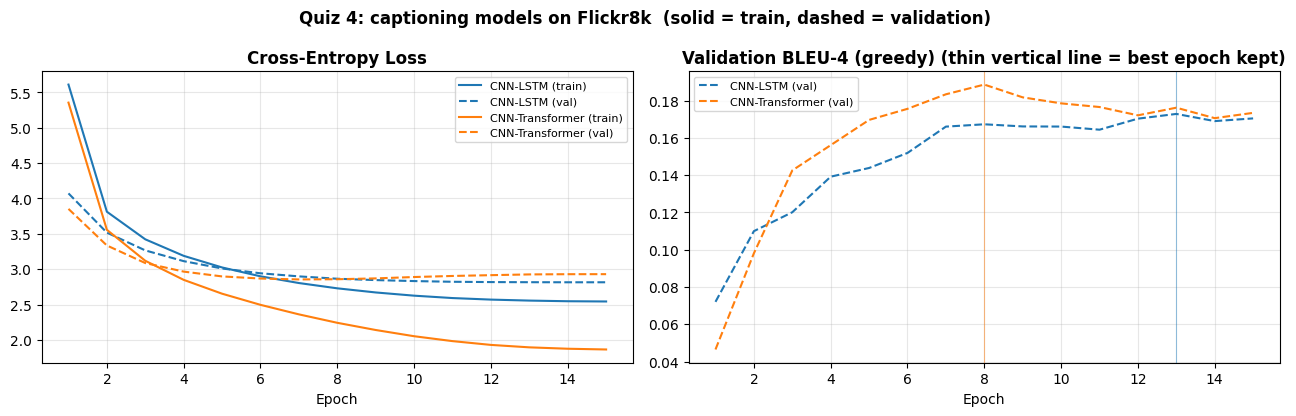

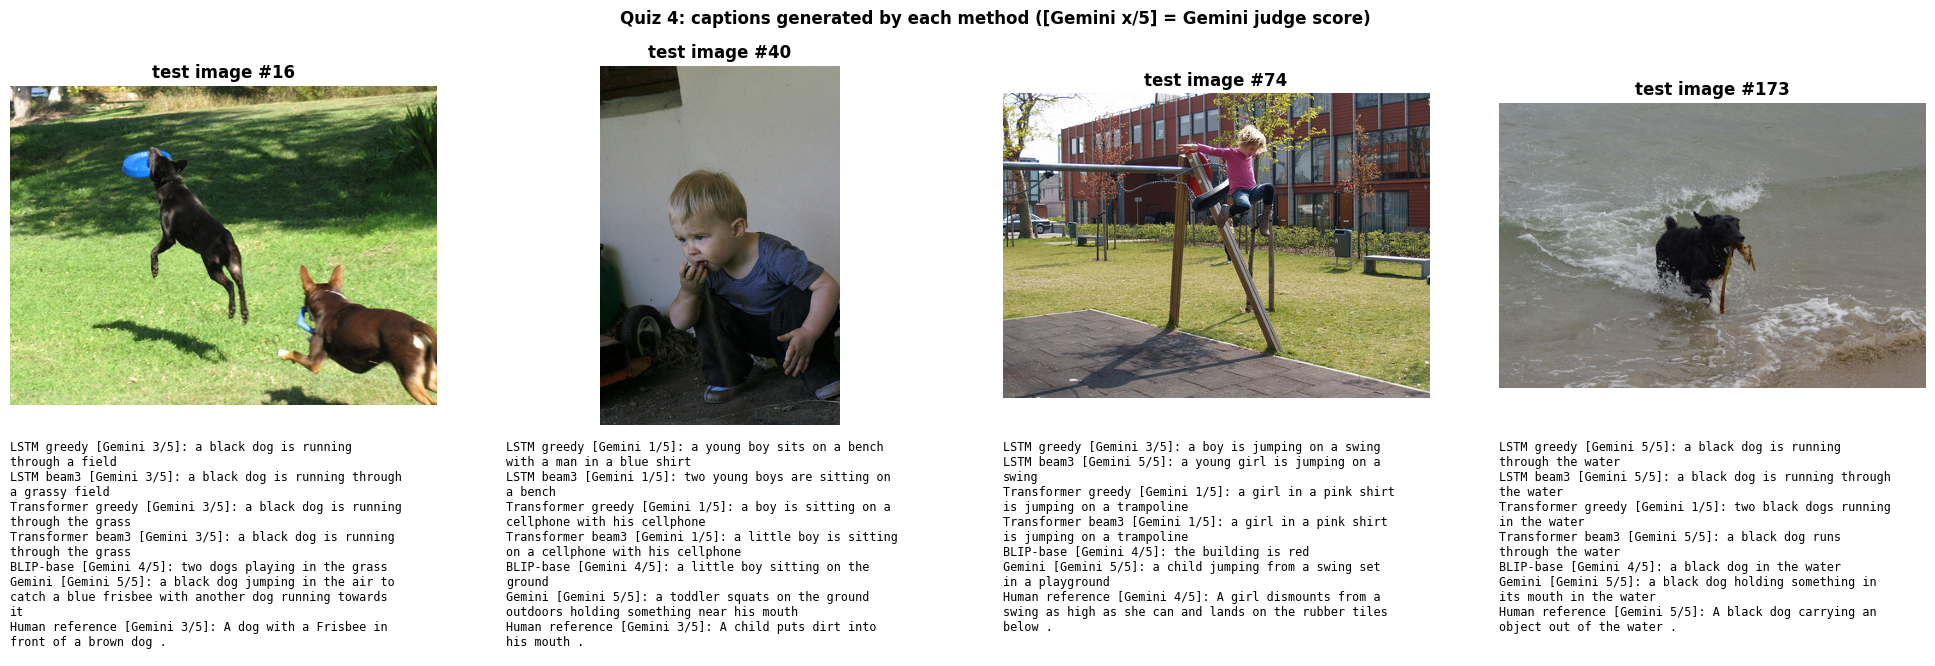

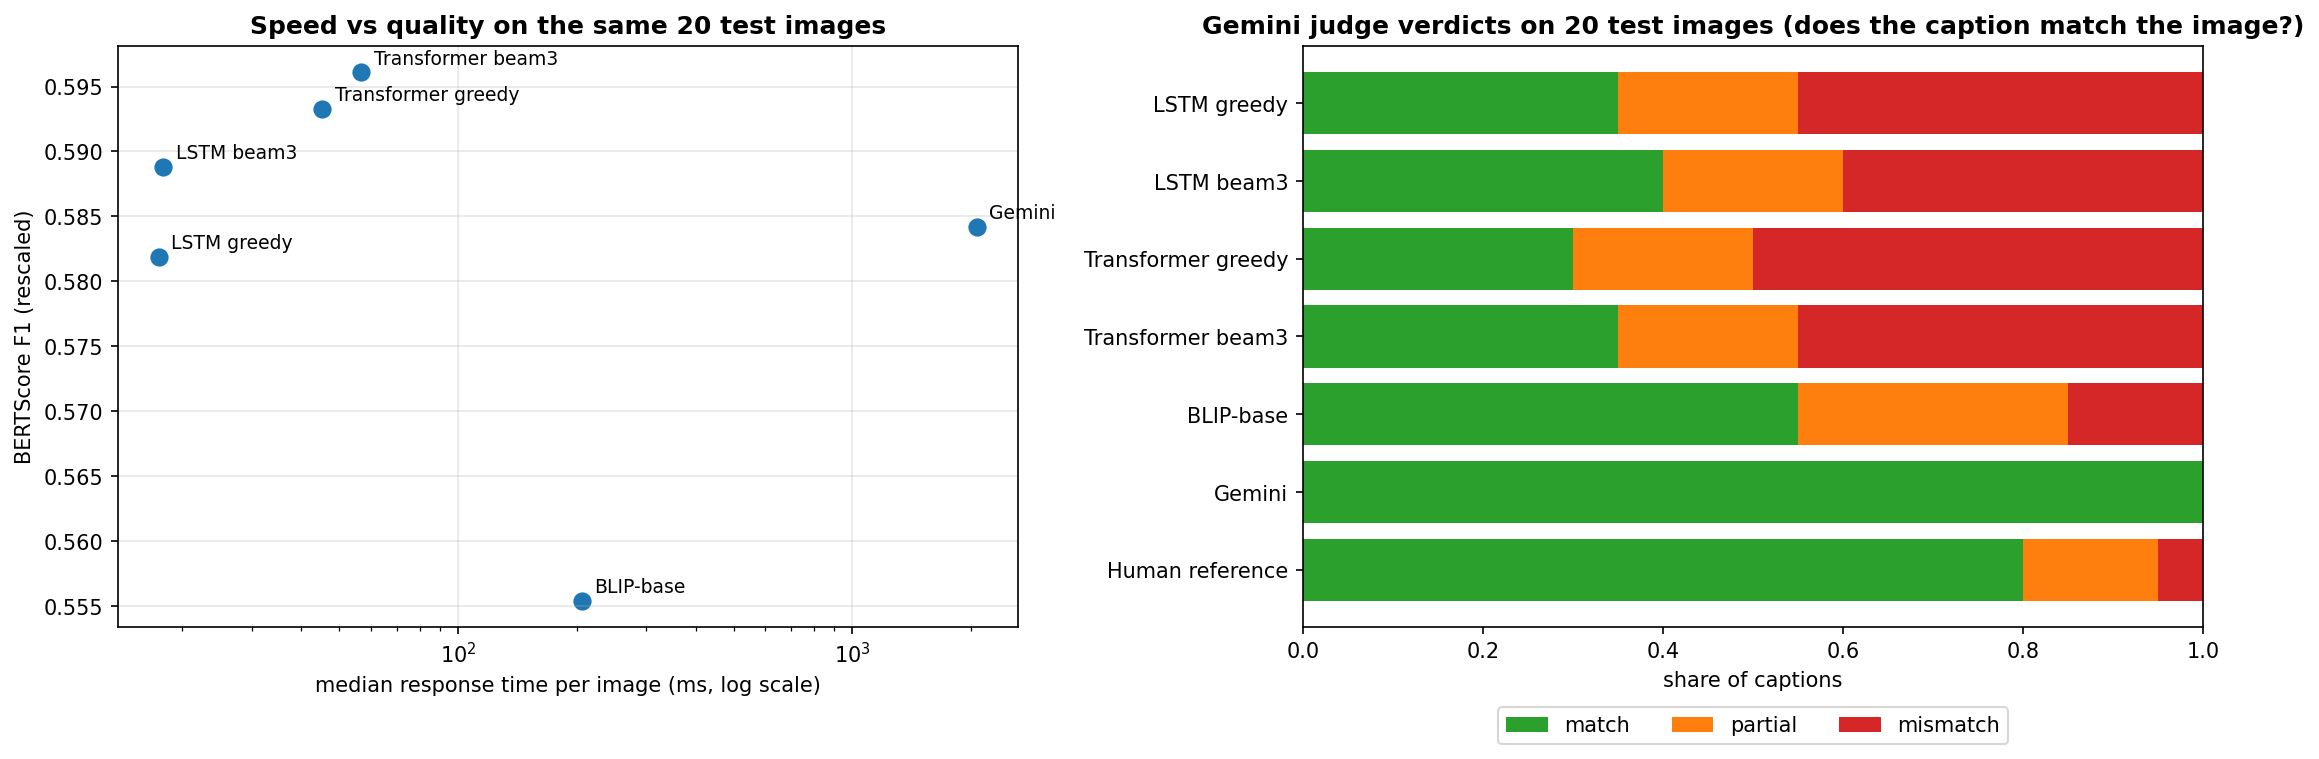

Gemini 判斷範例（前 3 張影像）：


,test_index,method,caption,verdict,score,reason
3,16,BLIP-base,two dogs playing in the grass,match,4,Correctly identifies two dogs playing in the grass.
0,16,Gemini,a black dog jumping in the air to catch a blue frisbee with another dog running towards it,match,5,"Accurately describes both dogs, the jumping black dog catching the frisbee, and the other running."
5,16,Human reference,a dog with a frisbee in front of a brown dog,partial,3,"The brown dog is actually in front/behind, and the black dog is jumping."
2,16,LSTM beam3,a black dog is running through a grassy field,partial,3,"The dog is jumping in the air, not running."
1,16,LSTM greedy,a black dog is running through a field,partial,3,"The black dog is jumping, not just running, and misses context of the second dog."
6,16,Transformer beam3,a black dog is running through the grass,partial,3,"The black dog is jumping in the air, not running on the ground."
4,16,Transformer greedy,a black dog is running through the grass,partial,3,The black dog is jumping in the air rather than running.
11,40,BLIP-base,a little boy sitting on the ground,partial,4,Little boy squatting on the ground.
12,40,Gemini,a toddler squats on the ground outdoors holding something near his mouth,match,5,Accurately describes the toddler squatting and holding something near mouth.
8,40,Human reference,a child puts dirt into his mouth,partial,3,"Child holds something near mouth, dirt is unconfirmed."


In [11]:
display(q4['figures']['curves'])
display(q4['figures']['samples'])
display(q4['figures']['tradeoff'])
if len(q4['judge']):
    print('Gemini 判斷範例（前 3 張影像）：')
    first = q4['judge']['test_index'].unique()[:3]
    display(q4['judge'][q4['judge']['test_index'].isin(first)].sort_values(['test_index', 'method']))

---
## 結果分析

各題的數據解讀、實驗結論與限制說明，整理在同目錄的 `README.md`。

In [12]:
# 打包下載結果（Output/ 與訓練紀錄 Checkpoints/*.json；模型權重太大不打包）
try:
    from google.colab import files
    !zip -q -r /content/HW04_results.zip Output Checkpoints -x "*.pt"
    files.download('/content/HW04_results.zip')
    print('已下載 HW04_results.zip；請另外用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。')
except ImportError:
    print('本機執行：結果已在 Output/ 與 Checkpoints/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

已下載 HW04_results.zip；請另外用「檔案 → 下載 → 下載 .ipynb」下載這份已執行的 Notebook。
